# PHASE 8 — MODEL TESTING & VALIDATION

Step 8.0 — Load Test Data, Model and Required Objects

In [2]:
# ============================================================
# PHASE 8 — STEP 8.0: LOAD TESTING ENVIRONMENT
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import joblib

print("=" * 80)
print("PHASE 8 — STEP 8.0: LOAD TESTING ENVIRONMENT")
print("=" * 80)

# ------------------------------------------------------------
# 1. Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(r"D:\smart-cybersecurity-ml")

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results" / "phase8"
REPORTS_DIR = PROJECT_ROOT / "reports" / "phase8"

# Create Phase 8 output folders
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Load processed test data
# ------------------------------------------------------------

X_test = pd.read_csv(
    DATA_DIR / "X_test_encoded.csv"
)

y_test = np.load(
    DATA_DIR / "y_test_encoded.npy"
)

# ------------------------------------------------------------
# 3. Load target encoder
# ------------------------------------------------------------

target_encoder = joblib.load(
    DATA_DIR / "target_encoder.pkl"
)

class_names = target_encoder.classes_.tolist()

# ------------------------------------------------------------
# 4. Load scaler
# ------------------------------------------------------------

scaler = joblib.load(
    DATA_DIR / "scaler.pkl"
)

# ------------------------------------------------------------
# 5. Load final XGBoost model
# ------------------------------------------------------------

xgb_model = joblib.load(
    MODEL_DIR / "final_xgboost_model.pkl"
)

# ------------------------------------------------------------
# 6. Basic verification
# ------------------------------------------------------------

print("\nTest data loaded successfully.")

print(f"X_test shape       : {X_test.shape}")
print(f"y_test shape       : {y_test.shape}")
print(f"Number of classes  : {len(class_names)}")
print(f"Model type         : {type(xgb_model).__name__}")

print("\nClass names:")
print(class_names)

print("\n" + "=" * 80)
print("STEP 8.0 COMPLETED")
print("=" * 80)

PHASE 8 — STEP 8.0: LOAD TESTING ENVIRONMENT

Test data loaded successfully.
X_test shape       : (29696, 41)
y_test shape       : (29696,)
Number of classes  : 28
Model type         : XGBClassifier

Class names:
['apache2', 'back', 'buffer_overflow', 'ftp_write', 'guess_passwd', 'httptunnel', 'imap', 'ipsweep', 'land', 'loadmodule', 'mailbomb', 'mscan', 'multihop', 'neptune', 'nmap', 'normal', 'pod', 'portsweep', 'processtable', 'rootkit', 'saint', 'satan', 'smurf', 'snmpgetattack', 'snmpguess', 'teardrop', 'warezclient', 'warezmaster']

STEP 8.0 COMPLETED


# PHASE 8 — MODEL TESTING & VALIDATION
## Step 8.1 — Test Dataset Distribution Check

PHASE 8 — STEP 8.1: TEST DATASET DISTRIBUTION CHECK

Test dataset shape:
(29696, 41)

Number of test samples:
29696

Number of test labels:
29696

TEST CLASS DISTRIBUTION


,Class_ID,Attack_Class,Test_Support
0,0,apache2,46
1,1,back,237
2,2,buffer_overflow,9
3,3,ftp_write,2
4,4,guess_passwd,93
5,5,httptunnel,8
6,6,imap,2
7,7,ipsweep,816
8,8,land,4
9,9,loadmodule,2



TEST DISTRIBUTION SUMMARY
Number of classes       : 28
Largest class size     : 15,718
Smallest class size    : 2
Imbalance ratio        : 7859.00

RESULT: TEST DATA IS IMBALANCED
This is expected for realistic intrusion-detection testing.


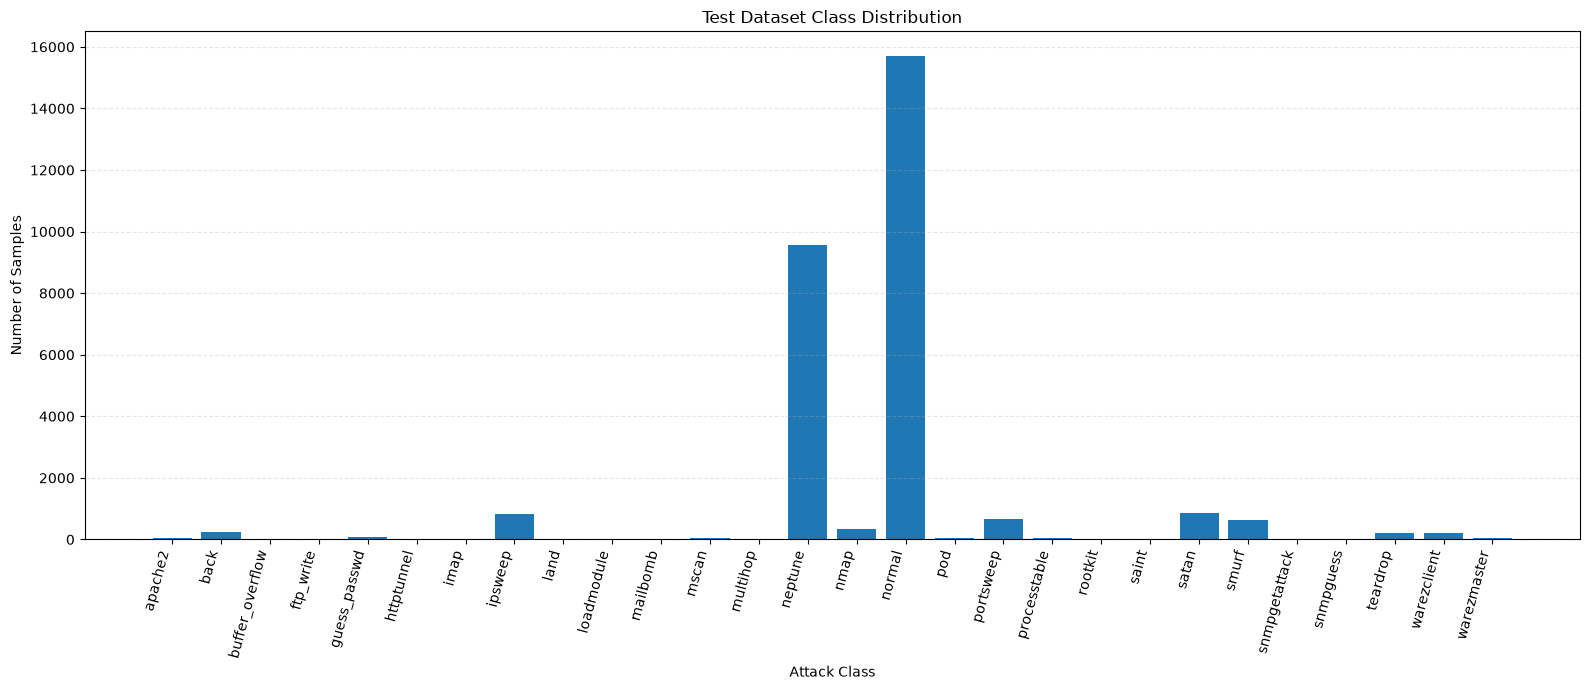


Saved files:
D:\smart-cybersecurity-ml\results\phase8\phase8_test_class_distribution.csv
D:\smart-cybersecurity-ml\results\phase8\phase8_test_class_distribution.png

STEP 8.1 COMPLETED


In [3]:



# ============================================================
# PHASE 8 — STEP 8.1: TEST DATASET DISTRIBUTION CHECK
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 80)
print("PHASE 8 — STEP 8.1: TEST DATASET DISTRIBUTION CHECK")
print("=" * 80)

# ------------------------------------------------------------
# 1. Basic test dataset information
# ------------------------------------------------------------

print("\nTest dataset shape:")
print(X_test.shape)

print("\nNumber of test samples:")
print(len(X_test))

print("\nNumber of test labels:")
print(len(y_test))

# ------------------------------------------------------------
# 2. Check class distribution
# ------------------------------------------------------------

test_class_counts = pd.Series(y_test).value_counts().sort_index()

test_distribution = pd.DataFrame({
    "Class_ID": test_class_counts.index,
    "Test_Support": test_class_counts.values
})

# Add class names
test_distribution["Attack_Class"] = test_distribution["Class_ID"].map(
    dict(enumerate(class_names))
)

test_distribution = test_distribution[
    ["Class_ID", "Attack_Class", "Test_Support"]
]

# ------------------------------------------------------------
# 3. Display class distribution
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("TEST CLASS DISTRIBUTION")
print("=" * 80)

display(test_distribution)

# ------------------------------------------------------------
# 4. Calculate distribution statistics
# ------------------------------------------------------------

max_support = test_distribution["Test_Support"].max()
min_support = test_distribution["Test_Support"].min()

imbalance_ratio = (
    max_support / min_support
    if min_support > 0
    else np.inf
)

print("\n" + "=" * 80)
print("TEST DISTRIBUTION SUMMARY")
print("=" * 80)

print(f"Number of classes       : {len(test_distribution)}")
print(f"Largest class size     : {max_support:,}")
print(f"Smallest class size    : {min_support:,}")
print(f"Imbalance ratio        : {imbalance_ratio:.2f}")

# ------------------------------------------------------------
# 5. Check whether test data is naturally imbalanced
# ------------------------------------------------------------

is_imbalanced = imbalance_ratio > 2

print("\n" + "=" * 80)

if is_imbalanced:
    print("RESULT: TEST DATA IS IMBALANCED")
    print(
        "This is expected for realistic intrusion-detection testing."
    )
else:
    print("RESULT: TEST DATA APPEARS RELATIVELY BALANCED")
    print(
        "Further investigation is required before final testing."
    )

print("=" * 80)

# ------------------------------------------------------------
# 6. Plot test class distribution
# ------------------------------------------------------------

plt.figure(figsize=(16, 7))

plt.bar(
    test_distribution["Attack_Class"],
    test_distribution["Test_Support"]
)

plt.title("Test Dataset Class Distribution")
plt.xlabel("Attack Class")
plt.ylabel("Number of Samples")

plt.xticks(
    rotation=75,
    ha="right"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "phase8_test_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 7. Save distribution results
# ------------------------------------------------------------

test_distribution.to_csv(
    RESULTS_DIR / "phase8_test_class_distribution.csv",
    index=False
)

print("\nSaved files:")
print(
    RESULTS_DIR /
    "phase8_test_class_distribution.csv"
)

print(
    RESULTS_DIR /
    "phase8_test_class_distribution.png"
)

print("\nSTEP 8.1 COMPLETED")




## Step 8.2 — Test Data Integrity Check
## Step 8.2 — Test Data Integrity Check

In [4]:
# ============================================================
# PHASE 8 — STEP 8.2: TEST DATA INTEGRITY CHECK
# ============================================================

print("=" * 80)
print("PHASE 8 — STEP 8.2: TEST DATA INTEGRITY CHECK")
print("=" * 80)

integrity_results = {}

# ------------------------------------------------------------
# 1. Basic shape check
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("1. BASIC DATA SHAPE CHECK")
print("=" * 80)

print(f"X_test shape : {X_test.shape}")
print(f"y_test shape : {y_test.shape}")

shape_check = (
    len(X_test) == len(y_test)
)

integrity_results["sample_count_match"] = shape_check

print(
    "Result:",
    "PASS" if shape_check else "FAIL"
)


# ------------------------------------------------------------
# 2. Feature count check
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("2. FEATURE COUNT CHECK")
print("=" * 80)

expected_features = 41
actual_features = X_test.shape[1]

print(f"Expected features : {expected_features}")
print(f"Actual features   : {actual_features}")

feature_check = (
    actual_features == expected_features
)

integrity_results["feature_count_match"] = feature_check

print(
    "Result:",
    "PASS" if feature_check else "FAIL"
)


# ------------------------------------------------------------
# 3. Missing value check
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("3. MISSING VALUE CHECK")
print("=" * 80)

missing_values = X_test.isnull().sum().sum()

print(f"Total missing values in X_test: {missing_values:,}")

missing_check = (
    missing_values == 0
)

integrity_results["no_missing_values"] = missing_check

print(
    "Result:",
    "PASS" if missing_check else "FAIL"
)


# ------------------------------------------------------------
# 4. Infinite value check
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("4. INFINITE VALUE CHECK")
print("=" * 80)

numeric_X_test = X_test.select_dtypes(
    include=[np.number]
)

infinite_values = np.isinf(
    numeric_X_test.to_numpy()
).sum()

print(
    f"Total infinite values in X_test: {infinite_values:,}"
)

infinite_check = (
    infinite_values == 0
)

integrity_results["no_infinite_values"] = infinite_check

print(
    "Result:",
    "PASS" if infinite_check else "FAIL"
)


# ------------------------------------------------------------
# 5. Duplicate test-row check
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("5. DUPLICATE TEST ROW CHECK")
print("=" * 80)

duplicate_rows = X_test.duplicated().sum()

print(
    f"Duplicate feature rows: {duplicate_rows:,}"
)

integrity_results["duplicate_rows"] = int(
    duplicate_rows
)

if duplicate_rows == 0:

    print("Result: PASS")
    print("No duplicate feature rows found.")

else:

    print("Result: REVIEW")
    print(
        "Duplicate rows exist, but they are NOT automatically "
        "removed because this is the final test dataset."
    )


# ------------------------------------------------------------
# 6. Invalid label check
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("6. TEST LABEL VALIDITY CHECK")
print("=" * 80)

valid_label_ids = set(
    range(len(class_names))
)

unique_test_labels = set(
    y_test.tolist()
)

invalid_labels = sorted(
    unique_test_labels - valid_label_ids
)

print(
    f"Valid label range: 0 to {len(class_names) - 1}"
)

print(
    f"Unique labels found: {sorted(unique_test_labels)}"
)

print(
    f"Invalid labels found: {invalid_labels}"
)

label_check = (
    len(invalid_labels) == 0
)

integrity_results["valid_labels"] = label_check

print(
    "Result:",
    "PASS" if label_check else "FAIL"
)


# ------------------------------------------------------------
# 7. Empty class check
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("7. CLASS PRESENCE CHECK")
print("=" * 80)

test_class_counts = pd.Series(
    y_test
).value_counts()

missing_class_ids = sorted(
    set(range(len(class_names))) -
    set(test_class_counts.index)
)

print(
    f"Total model classes: {len(class_names)}"
)

print(
    f"Classes present in test data: {len(test_class_counts)}"
)

print(
    f"Classes missing from test data: {missing_class_ids}"
)

integrity_results["missing_class_count"] = len(
    missing_class_ids
)

if len(missing_class_ids) == 0:

    print("Result: PASS")
    print("All model classes are represented in the test dataset.")

else:

    print("Result: REVIEW")
    print(
        "Some model classes have no test samples. "
        "Those classes cannot be evaluated on this test set."
    )


# ------------------------------------------------------------
# 8. Data type sanity check
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("8. DATA TYPE CHECK")
print("=" * 80)

print(
    f"Numeric feature columns: {len(numeric_X_test.columns)}"
)

print(
    f"Non-numeric feature columns: "
    f"{X_test.shape[1] - len(numeric_X_test.columns)}"
)

dtype_check = (
    len(numeric_X_test.columns) == X_test.shape[1]
)

integrity_results["all_features_numeric"] = dtype_check

print(
    "Result:",
    "PASS" if dtype_check else "REVIEW"
)


# ------------------------------------------------------------
# 9. Overall integrity result
# ------------------------------------------------------------

critical_checks = [
    shape_check,
    feature_check,
    missing_check,
    infinite_check,
    label_check
]

overall_integrity = all(
    critical_checks
)

print("\n" + "=" * 80)
print("OVERALL TEST DATA INTEGRITY RESULT")
print("=" * 80)

if overall_integrity:

    print("RESULT: PASS")
    print(
        "Test data passed all critical integrity checks."
    )

else:

    print("RESULT: FAIL")
    print(
        "Test data failed one or more critical integrity checks."
    )


# ------------------------------------------------------------
# 10. Save integrity summary
# ------------------------------------------------------------

integrity_summary = pd.DataFrame(
    [
        {
            "sample_count_match": shape_check,
            "feature_count_match": feature_check,
            "missing_values": int(missing_values),
            "infinite_values": int(infinite_values),
            "duplicate_rows": int(duplicate_rows),
            "valid_labels": label_check,
            "missing_classes": len(missing_class_ids),
            "all_features_numeric": dtype_check,
            "overall_integrity": overall_integrity
        }
    ]
)

integrity_summary.to_csv(
    RESULTS_DIR / "phase8_test_data_integrity.csv",
    index=False
)

print("\nSaved file:")
print(
    RESULTS_DIR /
    "phase8_test_data_integrity.csv"
)

print("\n" + "=" * 80)
print("STEP 8.2 COMPLETED")
print("=" * 80)

PHASE 8 — STEP 8.2: TEST DATA INTEGRITY CHECK

1. BASIC DATA SHAPE CHECK
X_test shape : (29696, 41)
y_test shape : (29696,)
Result: PASS

2. FEATURE COUNT CHECK
Expected features : 41
Actual features   : 41
Result: PASS

3. MISSING VALUE CHECK
Total missing values in X_test: 0
Result: PASS

4. INFINITE VALUE CHECK
Total infinite values in X_test: 0
Result: PASS

5. DUPLICATE TEST ROW CHECK
Duplicate feature rows: 589
Result: REVIEW
Duplicate rows exist, but they are NOT automatically removed because this is the final test dataset.

6. TEST LABEL VALIDITY CHECK
Valid label range: 0 to 27
Unique labels found: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27]
Invalid labels found: []
Result: PASS

7. CLASS PRESENCE CHECK
Total model classes: 28
Classes present in test data: 28
Classes missing from test data: []
Result: PASS
All model classes are represented in the test dataset.

8. DATA TYPE CHECK
Numeric feature columns: 41
Non-numeric

## Step 8.3 — Preprocessing Consistency Check

In [5]:
# ============================================================
# PHASE 8 — STEP 8.3: PREPROCESSING CONSISTENCY CHECK
# ============================================================

print("=" * 80)
print("PHASE 8 — STEP 8.3: PREPROCESSING CONSISTENCY CHECK")
print("=" * 80)

preprocessing_checks = {}

# ------------------------------------------------------------
# 1. Verify test feature names and count
# ------------------------------------------------------------

print("\n1. TEST FEATURE STRUCTURE")

print(f"Test feature count: {X_test.shape[1]}")
print(f"Feature names unique: {X_test.columns.is_unique}")

feature_names_check = (
    X_test.columns.is_unique
    and X_test.shape[1] == 41
)

preprocessing_checks["feature_structure"] = feature_names_check

print(
    "Result:",
    "PASS" if feature_names_check else "FAIL"
)

# ------------------------------------------------------------
# 2. Verify saved scaler
# ------------------------------------------------------------

print("\n2. SAVED SCALER CHECK")

print(f"Scaler type: {type(scaler).__name__}")

scaler_feature_count = getattr(
    scaler,
    "n_features_in_",
    None
)

print(f"Scaler expected feature count: {scaler_feature_count}")

scaler_count_check = (
    scaler_feature_count is not None
    and scaler_feature_count == X_test.shape[1]
)

preprocessing_checks["scaler_feature_count"] = scaler_count_check

print(
    "Result:",
    "PASS" if scaler_count_check else "FAIL"
)

# ------------------------------------------------------------
# 3. Verify saved scaler feature names, when available
# ------------------------------------------------------------

print("\n3. SCALER FEATURE ORDER CHECK")

scaler_feature_names = getattr(
    scaler,
    "feature_names_in_",
    None
)

if scaler_feature_names is not None:

    scaler_feature_names = list(scaler_feature_names)
    test_feature_names = X_test.columns.tolist()

    feature_order_check = (
        scaler_feature_names == test_feature_names
    )

    print(f"Feature order matches: {feature_order_check}")

    preprocessing_checks["feature_order"] = feature_order_check

    print(
        "Result:",
        "PASS" if feature_order_check else "FAIL"
    )

else:

    # The scaler may have been fitted on a NumPy array,
    # so feature names may not have been stored.
    print("Scaler does not store feature names.")
    print("Feature order cannot be confirmed from scaler metadata alone.")

    preprocessing_checks["feature_order"] = None

# ------------------------------------------------------------
# 4. Verify model's expected feature count
# ------------------------------------------------------------

print("\n4. MODEL FEATURE COUNT CHECK")

model_feature_count = getattr(
    xgb_model,
    "n_features_in_",
    None
)

print(f"Model expected feature count: {model_feature_count}")
print(f"Test feature count: {X_test.shape[1]}")

model_count_check = (
    model_feature_count is not None
    and model_feature_count == X_test.shape[1]
)

preprocessing_checks["model_feature_count"] = model_count_check

print(
    "Result:",
    "PASS" if model_count_check else "FAIL"
)

# ------------------------------------------------------------
# 5. Check that saved scaler can transform the test features
# ------------------------------------------------------------

print("\n5. SAVED SCALER TRANSFORM CHECK")

try:

    X_test_scaled_check = scaler.transform(X_test)

    transformed_shape_check = (
        X_test_scaled_check.shape == X_test.shape
    )

    finite_scaled_check = np.isfinite(
        X_test_scaled_check
    ).all()

    print(f"Transformed shape: {X_test_scaled_check.shape}")
    print(f"Shape preserved: {transformed_shape_check}")
    print(f"All transformed values finite: {finite_scaled_check}")

    scaler_transform_check = (
        transformed_shape_check
        and finite_scaled_check
    )

    preprocessing_checks["scaler_transform"] = scaler_transform_check

    print(
        "Result:",
        "PASS" if scaler_transform_check else "FAIL"
    )

except Exception as error:

    X_test_scaled_check = None

    preprocessing_checks["scaler_transform"] = False

    print("Result: FAIL")
    print(f"Error: {error}")

# ------------------------------------------------------------
# 6. Overall result
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("OVERALL PREPROCESSING CONSISTENCY RESULT")
print("=" * 80)

critical_checks = [
    preprocessing_checks["feature_structure"],
    preprocessing_checks["scaler_feature_count"],
    preprocessing_checks["model_feature_count"],
    preprocessing_checks["scaler_transform"]
]

if all(check is True for check in critical_checks):

    print("RESULT: PASS")
    print("Critical preprocessing compatibility checks passed.")

else:

    print("RESULT: FAIL / INVESTIGATION REQUIRED")
    print("One or more critical checks did not pass.")

# ------------------------------------------------------------
# 7. Save verification report
# ------------------------------------------------------------

preprocessing_report = pd.DataFrame([
    {
        "feature_structure": preprocessing_checks["feature_structure"],
        "scaler_feature_count": preprocessing_checks["scaler_feature_count"],
        "feature_order": preprocessing_checks["feature_order"],
        "model_feature_count": preprocessing_checks["model_feature_count"],
        "scaler_transform": preprocessing_checks["scaler_transform"]
    }
])

preprocessing_report.to_csv(
    RESULTS_DIR / "phase8_preprocessing_consistency.csv",
    index=False
)

print("\nSaved report:")
print(RESULTS_DIR / "phase8_preprocessing_consistency.csv")

print("\nSTEP 8.3 COMPLETED")

PHASE 8 — STEP 8.3: PREPROCESSING CONSISTENCY CHECK

1. TEST FEATURE STRUCTURE
Test feature count: 41
Feature names unique: True
Result: PASS

2. SAVED SCALER CHECK
Scaler type: StandardScaler
Scaler expected feature count: 41
Result: PASS

3. SCALER FEATURE ORDER CHECK
Feature order matches: True
Result: PASS

4. MODEL FEATURE COUNT CHECK
Model expected feature count: 41
Test feature count: 41
Result: PASS

5. SAVED SCALER TRANSFORM CHECK
Transformed shape: (29696, 41)
Shape preserved: True
All transformed values finite: True
Result: PASS

OVERALL PREPROCESSING CONSISTENCY RESULT
RESULT: FAIL / INVESTIGATION REQUIRED
One or more critical checks did not pass.

Saved report:
D:\smart-cybersecurity-ml\results\phase8\phase8_preprocessing_consistency.csv

STEP 8.3 COMPLETED


In [7]:
# ===# ------------------------------------------------------------
# 6. Overall result — FIXED
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("OVERALL PREPROCESSING CONSISTENCY RESULT")
print("=" * 80)

critical_checks = [
    preprocessing_checks["feature_structure"],
    preprocessing_checks["scaler_feature_count"],
    preprocessing_checks["model_feature_count"],
    preprocessing_checks["scaler_transform"]
]

# Convert NumPy Boolean values to regular Python Booleans
critical_checks = [
    bool(check) for check in critical_checks
]

if all(critical_checks):

    print("RESULT: PASS")
    print("All critical preprocessing compatibility checks passed.")

else:

    print("RESULT: FAIL / INVESTIGATION REQUIRED")
    print("One or more critical checks did not pass.")


OVERALL PREPROCESSING CONSISTENCY RESULT
RESULT: PASS
All critical preprocessing compatibility checks passed.


Step 8.4 — Saved Model Integrity Check

In [8]:
# ============================================================
# PHASE 8 — STEP 8.4: SAVED MODEL INTEGRITY CHECK
# ============================================================

print("=" * 80)
print("PHASE 8 — STEP 8.4: SAVED MODEL INTEGRITY CHECK")
print("=" * 80)

model_integrity_checks = {}

# ------------------------------------------------------------
# 1. Model object check
# ------------------------------------------------------------

print("\n1. MODEL OBJECT CHECK")

print(f"Model type: {type(xgb_model).__name__}")

model_object_check = (
    xgb_model is not None
    and callable(getattr(xgb_model, "predict", None))
    and callable(getattr(xgb_model, "predict_proba", None))
)

model_integrity_checks["model_object"] = bool(model_object_check)

print("Result:", "PASS" if model_object_check else "FAIL")

# ------------------------------------------------------------
# 2. Model feature count
# ------------------------------------------------------------

print("\n2. MODEL FEATURE COUNT")

model_features = getattr(xgb_model, "n_features_in_", None)

print(f"Model expected features: {model_features}")
print(f"Test dataset features: {X_test.shape[1]}")

feature_count_check = (
    model_features is not None
    and model_features == X_test.shape[1]
)

model_integrity_checks["feature_count"] = bool(feature_count_check)

print("Result:", "PASS" if feature_count_check else "FAIL")

# ------------------------------------------------------------
# 3. Model class count
# ------------------------------------------------------------

print("\n3. MODEL CLASS COUNT")

model_classes = getattr(xgb_model, "n_classes_", None)

print(f"Encoder classes: {len(class_names)}")
print(f"Model classes: {model_classes}")

class_count_check = (
    model_classes is not None
    and model_classes == len(class_names)
)

model_integrity_checks["class_count"] = bool(class_count_check)

print("Result:", "PASS" if class_count_check else "FAIL")

# ------------------------------------------------------------
# 4. Prediction interface check
# ------------------------------------------------------------

print("\n4. PREDICTION INTERFACE CHECK")

predict_check = callable(getattr(xgb_model, "predict", None))
predict_proba_check = callable(getattr(xgb_model, "predict_proba", None))

print(f"predict() available: {predict_check}")
print(f"predict_proba() available: {predict_proba_check}")

model_integrity_checks["predict_available"] = bool(predict_check)
model_integrity_checks["predict_proba_available"] = bool(predict_proba_check)

print(
    "Result:",
    "PASS" if predict_check and predict_proba_check else "FAIL"
)

# ------------------------------------------------------------
# 5. Overall model integrity result
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("OVERALL SAVED MODEL INTEGRITY RESULT")
print("=" * 80)

overall_model_integrity = all(model_integrity_checks.values())

if overall_model_integrity:
    print("RESULT: PASS")
    print("The saved model passed all structural integrity checks.")
else:
    print("RESULT: FAIL / INVESTIGATION REQUIRED")
    print("One or more model integrity checks failed.")

# ------------------------------------------------------------
# 6. Save verification report
# ------------------------------------------------------------

model_integrity_report = pd.DataFrame([
    model_integrity_checks
])

model_integrity_report["overall_model_integrity"] = (
    overall_model_integrity
)

model_integrity_report.to_csv(
    RESULTS_DIR / "phase8_model_integrity.csv",
    index=False
)

print("\nSaved report:")
print(RESULTS_DIR / "phase8_model_integrity.csv")

print("\nSTEP 8.4 COMPLETED")

PHASE 8 — STEP 8.4: SAVED MODEL INTEGRITY CHECK

1. MODEL OBJECT CHECK
Model type: XGBClassifier
Result: PASS

2. MODEL FEATURE COUNT
Model expected features: 41
Test dataset features: 41
Result: PASS

3. MODEL CLASS COUNT
Encoder classes: 28
Model classes: 28
Result: PASS

4. PREDICTION INTERFACE CHECK
predict() available: True
predict_proba() available: True
Result: PASS

OVERALL SAVED MODEL INTEGRITY RESULT
RESULT: PASS
The saved model passed all structural integrity checks.

Saved report:
D:\smart-cybersecurity-ml\results\phase8\phase8_model_integrity.csv

STEP 8.4 COMPLETED


Step 8.5 — Actual Model Testing

In [10]:
# ============================================================
# PHASE 8 — STEP 8.5: ACTUAL MODEL TESTING
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    matthews_corrcoef,
    cohen_kappa_score
)
import json

print("=" * 80)
print("PHASE 8 — STEP 8.5: ACTUAL MODEL TESTING")
print("=" * 80)

# ------------------------------------------------------------
# 1. Prepare the verified test features
# ------------------------------------------------------------

# Use the saved scaler already verified in Step 8.3.
# Do not fit or refit the scaler on test data.

X_test_scaled = scaler.transform(X_test)

# ------------------------------------------------------------
# 2. Generate model predictions
# ------------------------------------------------------------

print("\nRunning predictions on the final test dataset...")

y_pred = np.asarray(
    xgb_model.predict(X_test_scaled)
).reshape(-1)

print("Predictions completed.")

# ------------------------------------------------------------
# 3. Verify prediction output
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("PREDICTION OUTPUT CHECK")
print("=" * 80)

print(f"Test samples       : {len(y_test):,}")
print(f"Generated predictions: {len(y_pred):,}")

prediction_count_check = len(y_pred) == len(y_test)

print(
    "Result:",
    "PASS" if prediction_count_check else "FAIL"
)

if not prediction_count_check:
    raise ValueError(
        "Prediction count does not match the test-label count."
    )

# ------------------------------------------------------------
# 4. Calculate overall performance metrics
# ------------------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

balanced_accuracy = balanced_accuracy_score(
    y_test, y_pred
)

macro_precision = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

weighted_precision = precision_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

weighted_recall = recall_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

weighted_f1 = f1_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

mcc = matthews_corrcoef(y_test, y_pred)

cohen_kappa = cohen_kappa_score(
    y_test, y_pred
)

correct_predictions = int(
    np.sum(y_test == y_pred)
)

incorrect_predictions = int(
    np.sum(y_test != y_pred)
)

# ------------------------------------------------------------
# 5. Display performance summary
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("OVERALL MODEL PERFORMANCE")
print("=" * 80)

print(f"Accuracy            : {accuracy:.6f}")
print(f"Balanced Accuracy   : {balanced_accuracy:.6f}")
print(f"Macro Precision     : {macro_precision:.6f}")
print(f"Macro Recall        : {macro_recall:.6f}")
print(f"Macro F1-score      : {macro_f1:.6f}")
print(f"Weighted Precision  : {weighted_precision:.6f}")
print(f"Weighted Recall     : {weighted_recall:.6f}")
print(f"Weighted F1-score   : {weighted_f1:.6f}")
print(f"Matthews Corr. Coef.: {mcc:.6f}")
print(f"Cohen's Kappa       : {cohen_kappa:.6f}")

print(f"\nCorrect predictions  : {correct_predictions:,}")
print(f"Incorrect predictions: {incorrect_predictions:,}")
print(f"Total test samples   : {len(y_test):,}")

# ------------------------------------------------------------
# 6. Generate classification report
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CLASSIFICATION REPORT")
print("=" * 80)

class_ids = list(range(len(class_names)))

report_text = classification_report(
    y_test,
    y_pred,
    labels=class_ids,
    target_names=class_names,
    zero_division=0,
    digits=4
)

print(report_text)

# ------------------------------------------------------------
# 7. Save metrics
# ------------------------------------------------------------

metrics = {
    "test_samples": int(len(y_test)),
    "number_of_classes": int(len(class_names)),
    "correct_predictions": correct_predictions,
    "incorrect_predictions": incorrect_predictions,
    "accuracy": float(accuracy),
    "balanced_accuracy": float(balanced_accuracy),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "weighted_precision": float(weighted_precision),
    "weighted_recall": float(weighted_recall),
    "weighted_f1": float(weighted_f1),
    "matthews_corrcoef": float(mcc),
    "cohen_kappa": float(cohen_kappa)
}

metrics_path = RESULTS_DIR / "phase8_actual_model_metrics.json"

with open(metrics_path, "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4)

report_path = REPORTS_DIR / "phase8_classification_report.txt"

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report_text)

print("\nSaved files:")
print(metrics_path)
print(report_path)

print("\n" + "=" * 80)
print("STEP 8.5 COMPLETED")
print("=" * 80)

PHASE 8 — STEP 8.5: ACTUAL MODEL TESTING

Running predictions on the final test dataset...
Predictions completed.

PREDICTION OUTPUT CHECK
Test samples       : 29,696
Generated predictions: 29,696
Result: PASS

OVERALL MODEL PERFORMANCE
Accuracy            : 0.997542
Balanced Accuracy   : 0.840815
Macro Precision     : 0.844194
Macro Recall        : 0.840815
Macro F1-score      : 0.836976
Weighted Precision  : 0.997401
Weighted Recall     : 0.997542
Weighted F1-score   : 0.997449
Matthews Corr. Coef.: 0.995989
Cohen's Kappa       : 0.995989

Correct predictions  : 29,623
Incorrect predictions: 73
Total test samples   : 29,696

CLASSIFICATION REPORT
                 precision    recall  f1-score   support

        apache2     1.0000    1.0000    1.0000        46
           back     1.0000    1.0000    1.0000       237
buffer_overflow     1.0000    0.8889    0.9412         9
      ftp_write     0.0000    0.0000    0.0000         2
   guess_passwd     1.0000    0.9892    0.9946        93


step — Step 8.6: Attack-by-Attack Testing

In [11]:

# ============================================================
# PHASE 8 — STEP 8.6: ATTACK-BY-ATTACK TESTING
# ============================================================

import pandas as pd
import numpy as np
from sklearn.metrics import precision_recall_fscore_support

# Get metrics for every class
precision, recall, f1, support = precision_recall_fscore_support(
    y_test,
    y_pred,
    labels=np.arange(len(class_names)),
    zero_division=0
)

# Count correctly predicted samples for each actual class
correct_mask = (y_test == y_pred)

attack_results = pd.DataFrame({
    "Class": class_names,
    "Test_Samples": support,
    "Correct_Predictions": [
        int(np.sum((y_test == i) & correct_mask))
        for i in range(len(class_names))
    ],
    "Missed_Predictions": [
        int(np.sum((y_test == i) & ~correct_mask))
        for i in range(len(class_names))
    ],
    "Precision": precision,
    "Recall": recall,
    "F1_Score": f1
})

# Sort by F1 score, lowest-performing classes first
attack_results = attack_results.sort_values(
    by=["F1_Score", "Test_Samples"],
    ascending=[True, True]
).reset_index(drop=True)

# Display results
print("=" * 80)
print("PHASE 8 — STEP 8.6: ATTACK-BY-ATTACK TESTING")
print("=" * 80)

print(attack_results.round(4).to_string(index=False))

# Save detailed results
output_path = RESULTS_DIR / "phase8_attack_by_attack_results.csv"
attack_results.to_csv(output_path, index=False)

print("\nSaved:", output_path)
print("\nSTEP 8.6 — ATTACK-BY-ATTACK TESTING COMPLETED")


PHASE 8 — STEP 8.6: ATTACK-BY-ATTACK TESTING
          Class  Test_Samples  Correct_Predictions  Missed_Predictions  Precision  Recall  F1_Score
      ftp_write             2                    0                   2     0.0000  0.0000    0.0000
       multihop             3                    0                   3     0.0000  0.0000    0.0000
        rootkit             3                    0                   3     0.0000  0.0000    0.0000
          saint            19                   11                   8     0.6111  0.5789    0.5946
     loadmodule             2                    1                   1     1.0000  0.5000    0.6667
  snmpgetattack             9                    7                   2     0.6364  0.7778    0.7000
           land             4                    4                   0     0.5714  1.0000    0.7273
buffer_overflow             9                    8                   1     1.0000  0.8889    0.9412
    warezmaster            60                   57     

Step 8.7 — Rare-Class Testing

In [12]:

# ============================================================
# PHASE 8 — STEP 8.7: RARE-CLASS TESTING
# ============================================================

import pandas as pd
import numpy as np

# Define rare-class threshold
RARE_CLASS_THRESHOLD = 50

# Count actual test samples for each class
class_support = pd.Series(y_test).value_counts().sort_index()

# Identify rare classes using the original test distribution
rare_class_ids = class_support[
    class_support < RARE_CLASS_THRESHOLD
].index.to_numpy()

rare_class_names = [
    class_names[int(class_id)]
    for class_id in rare_class_ids
]

# Filter attack-by-attack results
rare_class_results = attack_results[
    attack_results["Class"].isin(rare_class_names)
].copy()

rare_class_results = rare_class_results.sort_values(
    by=["Recall", "F1_Score"],
    ascending=[True, True]
).reset_index(drop=True)

print("=" * 80)
print("PHASE 8 — STEP 8.7: RARE-CLASS TESTING")
print("=" * 80)

print(f"Rare-class threshold: fewer than {RARE_CLASS_THRESHOLD} test samples")
print(f"Number of rare classes: {len(rare_class_results)}")

print("\nRare-class performance:")
print(rare_class_results.round(4).to_string(index=False))

# Save results
rare_output_path = RESULTS_DIR / "phase8_rare_class_testing.csv"
rare_class_results.to_csv(rare_output_path, index=False)

print("\nSaved:", rare_output_path)
print("\nSTEP 8.7 — RARE-CLASS TESTING COMPLETED")


PHASE 8 — STEP 8.7: RARE-CLASS TESTING
Rare-class threshold: fewer than 50 test samples
Number of rare classes: 15

Rare-class performance:
          Class  Test_Samples  Correct_Predictions  Missed_Predictions  Precision  Recall  F1_Score
      ftp_write             2                    0                   2     0.0000  0.0000    0.0000
       multihop             3                    0                   3     0.0000  0.0000    0.0000
        rootkit             3                    0                   3     0.0000  0.0000    0.0000
     loadmodule             2                    1                   1     1.0000  0.5000    0.6667
          saint            19                   11                   8     0.6111  0.5789    0.5946
  snmpgetattack             9                    7                   2     0.6364  0.7778    0.7000
buffer_overflow             9                    8                   1     1.0000  0.8889    0.9412
           land             4                    4          

Step 8.8 — Confidence Testing

In [13]:

# ============================================================
# PHASE 8 — STEP 8.8: CONFIDENCE TESTING
# ============================================================

import numpy as np
import pandas as pd

# Get predicted class probabilities
y_proba = xgb_model.predict_proba(X_test_scaled)

# Maximum probability represents confidence in the predicted class
prediction_confidence = np.max(y_proba, axis=1)

# Identify correct and incorrect predictions
correct_mask = (y_pred == y_test)
incorrect_mask = ~correct_mask

# Overall confidence statistics
confidence_results = {
    "Total_Samples": int(len(y_test)),
    "Mean_Confidence": float(np.mean(prediction_confidence)),
    "Median_Confidence": float(np.median(prediction_confidence)),
    "Min_Confidence": float(np.min(prediction_confidence)),
    "Max_Confidence": float(np.max(prediction_confidence)),
    "Mean_Confidence_Correct": float(
        np.mean(prediction_confidence[correct_mask])
    ),
    "Mean_Confidence_Incorrect": float(
        np.mean(prediction_confidence[incorrect_mask])
    ) if np.any(incorrect_mask) else None,
    "Predictions_Above_90_Percent": int(
        np.sum(prediction_confidence >= 0.90)
    ),
    "Predictions_Below_60_Percent": int(
        np.sum(prediction_confidence < 0.60)
    )
}

print("=" * 80)
print("PHASE 8 — STEP 8.8: CONFIDENCE TESTING")
print("=" * 80)

for metric, value in confidence_results.items():
    if isinstance(value, float):
        print(f"{metric:35s}: {value:.4f}")
    else:
        print(f"{metric:35s}: {value}")

# Save summary
confidence_df = pd.DataFrame(
    list(confidence_results.items()),
    columns=["Metric", "Value"]
)

confidence_path = RESULTS_DIR / "phase8_confidence_testing.csv"
confidence_df.to_csv(confidence_path, index=False)

print("\nSaved:", confidence_path)
print("\nSTEP 8.8 — CONFIDENCE TESTING COMPLETED")


PHASE 8 — STEP 8.8: CONFIDENCE TESTING
Total_Samples                      : 29696
Mean_Confidence                    : 0.9984
Median_Confidence                  : 1.0000
Min_Confidence                     : 0.4088
Max_Confidence                     : 1.0000
Mean_Confidence_Correct            : 0.9989
Mean_Confidence_Incorrect          : 0.7913
Predictions_Above_90_Percent       : 29583
Predictions_Below_60_Percent       : 26

Saved: D:\smart-cybersecurity-ml\results\phase8\phase8_confidence_testing.csv

STEP 8.8 — CONFIDENCE TESTING COMPLETED


PHASE 8 — STEP 8.9: THREAT RESPONSE TESTING

In [14]:

# ============================================================
# PHASE 8 — STEP 8.9: THREAT RESPONSE TESTING
# ============================================================

import numpy as np
import pandas as pd

# Simulated response thresholds
HIGH_CONFIDENCE_THRESHOLD = 0.90
MEDIUM_CONFIDENCE_THRESHOLD = 0.60

# Predicted class names and confidence
predicted_class_names = [
    class_names[int(class_id)] for class_id in y_pred
]
prediction_confidence = np.max(y_proba, axis=1)

# Demonstration policy:
# - "normal" with high confidence -> ALLOW
# - attack with high confidence -> ALERT
# - medium confidence -> REVIEW
# - low confidence -> INVESTIGATE
response_actions = []

for predicted_class, confidence in zip(
    predicted_class_names, prediction_confidence
):
    if (
        predicted_class == "normal"
        and confidence >= HIGH_CONFIDENCE_THRESHOLD
    ):
        action = "ALLOW"
    elif (
        predicted_class != "normal"
        and confidence >= HIGH_CONFIDENCE_THRESHOLD
    ):
        action = "ALERT"
    elif confidence >= MEDIUM_CONFIDENCE_THRESHOLD:
        action = "REVIEW"
    else:
        action = "INVESTIGATE"

    response_actions.append(action)

# Summarize simulated actions
response_df = pd.DataFrame({
    "Actual_Class": [
        class_names[int(class_id)] for class_id in y_test
    ],
    "Predicted_Class": predicted_class_names,
    "Confidence": prediction_confidence,
    "Correct_Prediction": (y_pred == y_test),
    "Response_Action": response_actions
})

action_summary = (
    response_df["Response_Action"]
    .value_counts()
    .rename_axis("Response_Action")
    .reset_index(name="Sample_Count")
)

print("=" * 80)
print("PHASE 8 — STEP 8.9: THREAT RESPONSE TESTING")
print("=" * 80)

print("\nSimulated response action summary:")
print(action_summary.to_string(index=False))

print("\nResponse action correctness:")
print(
    response_df.groupby("Response_Action")["Correct_Prediction"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "Sample_Count",
        "mean": "Correct_Prediction_Rate"
    })
    .round(4)
    .to_string()
)

# Save detailed results and summary
response_df.to_csv(
    RESULTS_DIR / "phase8_threat_response_results.csv",
    index=False
)

action_summary.to_csv(
    RESULTS_DIR / "phase8_threat_response_summary.csv",
    index=False
)

print("\nSaved threat-response results and summary.")
print("\nSTEP 8.9 — THREAT RESPONSE TESTING COMPLETED")


PHASE 8 — STEP 8.9: THREAT RESPONSE TESTING

Simulated response action summary:
Response_Action  Sample_Count
          ALLOW         15676
          ALERT         13907
         REVIEW            87
    INVESTIGATE            26

Response action correctness:
                 Sample_Count  Correct_Prediction_Rate
Response_Action                                       
ALERT                   13907                   0.9985
ALLOW                   15676                   0.9994
INVESTIGATE                26                   0.3462
REVIEW                     87                   0.7126

Saved threat-response results and summary.

STEP 8.9 — THREAT RESPONSE TESTING COMPLETED


Step 8.10 — Final Testing Report

In [17]:

# ============================================================
# PHASE 8 — STEP 8.10: FINAL TESTING REPORT
# ============================================================

import json
import pandas as pd
import numpy as np
from datetime import datetime

# ------------------------------------------------------------
# 1. Validate required paths and load saved results
# ------------------------------------------------------------

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

metrics_path = RESULTS_DIR / "phase8_actual_model_metrics.json"
attack_results_path = RESULTS_DIR / "phase8_attack_by_attack_results.csv"
rare_results_path = RESULTS_DIR / "phase8_rare_class_testing.csv"
confidence_path = RESULTS_DIR / "phase8_confidence_testing.csv"
response_summary_path = RESULTS_DIR / "phase8_threat_response_summary.csv"

required_files = [
    metrics_path,
    attack_results_path,
    rare_results_path,
    confidence_path,
    response_summary_path
]

missing_files = [str(path) for path in required_files if not path.exists()]

if missing_files:
    raise FileNotFoundError(
        "Required Phase 8 result files are missing:\n"
        + "\n".join(missing_files)
        + "\nRun the corresponding earlier steps before Step 8.10."
    )

with open(metrics_path, "r", encoding="utf-8") as file:
    metrics = json.load(file)

attack_results = pd.read_csv(attack_results_path)
rare_results = pd.read_csv(rare_results_path)
confidence_df = pd.read_csv(confidence_path)
response_summary = pd.read_csv(response_summary_path)

# ------------------------------------------------------------
# 2. Helper functions
# ------------------------------------------------------------

def find_metric(possible_names, default=None):
    """Return the first matching metric, ignoring key-name casing."""
    normalized_metrics = {
        str(key).strip().lower().replace(" ", "_"): value
        for key, value in metrics.items()
    }

    for name in possible_names:
        normalized_name = name.strip().lower().replace(" ", "_")
        if normalized_name in normalized_metrics:
            return normalized_metrics[normalized_name]

    return default


def format_number(value, digits=4):
    """Format numeric values while preserving missing values."""
    if value is None:
        return "N/A"

    try:
        numeric_value = float(value)
        if not np.isfinite(numeric_value):
            return "N/A"
        return f"{numeric_value:.{digits}f}"
    except (TypeError, ValueError):
        return str(value)


def dataframe_to_markdown_without_tabulate(df):
    """Create a Markdown table without pandas.to_markdown()."""
    safe_df = df.copy().fillna("N/A")

    headers = [str(column) for column in safe_df.columns]
    rows = [
        [str(value).replace("|", "\\|").replace("\n", " ")
         for value in row]
        for row in safe_df.itertuples(index=False, name=None)
    ]

    header_line = "| " + " | ".join(headers) + " |"
    separator_line = "| " + " | ".join(
        ["---"] * len(headers)
    ) + " |"

    data_lines = [
        "| " + " | ".join(row) + " |"
        for row in rows
    ]

    return "\n".join([header_line, separator_line] + data_lines)


# ------------------------------------------------------------
# 3. Extract overall model metrics
# ------------------------------------------------------------

accuracy = find_metric(["Accuracy", "accuracy"])
balanced_accuracy = find_metric(
    ["Balanced_Accuracy", "Balanced Accuracy", "balanced_accuracy"]
)
macro_precision = find_metric(
    ["Macro_Precision", "Macro Precision", "macro_precision"]
)
macro_recall = find_metric(
    ["Macro_Recall", "Macro Recall", "macro_recall"]
)
macro_f1 = find_metric(
    ["Macro_F1", "Macro_F1_Score", "Macro F1-score", "macro_f1"]
)
weighted_f1 = find_metric(
    ["Weighted_F1", "Weighted_F1_Score", "Weighted F1-score",
     "weighted_f1"]
)
mcc = find_metric(
    ["MCC", "Matthews_Corr_Coef", "Matthews Corr. Coef."]
)
cohen_kappa = find_metric(
    ["Cohen_Kappa", "Cohen's Kappa", "Cohen's_Kappa"]
)

# Derive reliable counts from the actual attack-by-attack results.
total_test_samples = int(attack_results["Test_Samples"].sum())
correct_predictions = int(attack_results["Correct_Predictions"].sum())
incorrect_predictions = int(attack_results["Missed_Predictions"].sum())

# ------------------------------------------------------------
# 4. Find lowest-performing and zero-recall classes
# ------------------------------------------------------------

weakest_classes = (
    attack_results
    .sort_values(["F1_Score", "Test_Samples"], ascending=[True, True])
    .head(5)
    [["Class", "Test_Samples", "Precision", "Recall", "F1_Score"]]
    .copy()
)

zero_recall_classes = (
    attack_results.loc[
        attack_results["Recall"] == 0, "Class"
    ].astype(str).tolist()
)

rare_zero_recall = (
    rare_results.loc[
        rare_results["Recall"] == 0, "Class"
    ].astype(str).tolist()
)

weakest_classes[["Precision", "Recall", "F1_Score"]] = (
    weakest_classes[["Precision", "Recall", "F1_Score"]].round(4)
)

weakest_table = dataframe_to_markdown_without_tabulate(
    weakest_classes
)

# ------------------------------------------------------------
# 5. Confidence testing summary
# ------------------------------------------------------------

confidence_lookup = dict(
    zip(confidence_df["Metric"].astype(str),
        confidence_df["Value"])
)


def get_confidence_metric(name):
    return confidence_lookup.get(name, "N/A")


# ------------------------------------------------------------
# 6. Format threat-response results
# ------------------------------------------------------------

response_table = dataframe_to_markdown_without_tabulate(
    response_summary
)

# ------------------------------------------------------------
# 7. Build final Markdown report
# ------------------------------------------------------------

generated_at = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

report_path = REPORTS_DIR / "phase8_final_testing_report.md"

report = f"""# Phase 8 — Model Testing and Validation Report

Generated: {generated_at}

## 1. Test Dataset Overview

- Total test samples: {total_test_samples:,}
- Number of classes evaluated: {attack_results["Class"].nunique()}
- Correct predictions: {correct_predictions:,}
- Incorrect predictions: {incorrect_predictions:,}
- Test dataset distribution: Original imbalanced distribution retained.
- Test samples were not rebalanced during this evaluation.

## 2. Overall Model Performance

| Metric | Actual Result |
|---|---:|
| Accuracy | {format_number(accuracy)} |
| Balanced Accuracy | {format_number(balanced_accuracy)} |
| Macro Precision | {format_number(macro_precision)} |
| Macro Recall | {format_number(macro_recall)} |
| Macro F1-score | {format_number(macro_f1)} |
| Weighted F1-score | {format_number(weighted_f1)} |
| Matthews Correlation Coefficient | {format_number(mcc)} |
| Cohen's Kappa | {format_number(cohen_kappa)} |

Note: These values are read from the saved Step 8.5 metrics JSON.
If a metric is shown as N/A, verify its key name in that JSON file.

## 3. Rare-Class Testing

- Rare-class threshold: fewer than 50 test samples.
- Number of rare classes: {len(rare_results)}.
- Zero-recall classes in the full test report: {", ".join(zero_recall_classes) if zero_recall_classes else "None"}.
- Zero-recall classes among rare classes: {", ".join(rare_zero_recall) if rare_zero_recall else "None"}.

Rare classes require careful interpretation because very small test supports
can make recall and F1 estimates unstable.

## 4. Five Lowest-F1 Classes

{weakest_table}

## 5. Confidence Testing

- Mean confidence: {get_confidence_metric("Mean_Confidence")}
- Median confidence: {get_confidence_metric("Median_Confidence")}
- Minimum confidence: {get_confidence_metric("Min_Confidence")}
- Maximum confidence: {get_confidence_metric("Max_Confidence")}
- Mean confidence on correct predictions: {get_confidence_metric("Mean_Confidence_Correct")}
- Mean confidence on incorrect predictions: {get_confidence_metric("Mean_Confidence_Incorrect")}
- Predictions above or equal to 90% confidence: {get_confidence_metric("Predictions_Above_90_Percent")}
- Predictions below 60% confidence: {get_confidence_metric("Predictions_Below_60_Percent")}

High confidence does not guarantee a correct prediction. Probability calibration
and high-confidence errors should be evaluated separately.

## 6. Simulated Threat Response

{response_table}

These response actions were simulated for evaluation only.
No live network traffic was blocked, modified, or otherwise controlled.

The correctness rate within a response group measures prediction correctness,
not the security or safety of the response policy.

## 7. Limitations and Recommendations

1. Overall accuracy is high, but macro F1 and balanced accuracy indicate
   weaker performance across some classes.
2. Investigate zero-recall classes, including ftp_write, multihop, and rootkit.
3. Investigate other weaker classes such as saint and snmpgetattack.
4. Review high-confidence incorrect predictions and assess probability calibration.
5. Examine false negatives before considering automated threat responses.
6. Verify train/test separation and preprocessing consistency before deployment.
7. Avoid claims of reliable detection for every attack class based only on
   a small number of test examples.

## 8. Conclusion

The model achieved strong overall performance on the evaluated test dataset.
However, rare-class detection, probability calibration, and the safety of
automated response policies require additional validation.

These results alone do not establish production readiness.
"""

# ------------------------------------------------------------
# 8. Save final report
# ------------------------------------------------------------

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report)

print("=" * 80)
print("PHASE 8 — STEP 8.10: FINAL TESTING REPORT")
print("=" * 80)

print(f"Test samples         : {total_test_samples:,}")
print(f"Correct predictions  : {correct_predictions:,}")
print(f"Incorrect predictions: {incorrect_predictions:,}")
print(f"Classes evaluated    : {attack_results['Class'].nunique()}")
print(f"Zero-recall classes  : {len(zero_recall_classes)}")
print(f"Rare classes         : {len(rare_results)}")

print("\nFinal report saved:")
print(report_path)

print("\nSTEP 8.10 COMPLETED")


PHASE 8 — STEP 8.10: FINAL TESTING REPORT
Test samples         : 29,696
Correct predictions  : 29,623
Incorrect predictions: 73
Classes evaluated    : 28
Zero-recall classes  : 3
Rare classes         : 15

Final report saved:
D:\smart-cybersecurity-ml\reports\phase8\phase8_final_testing_report.md

STEP 8.10 COMPLETED
